# GIRO 2026 — how the matrix completion works

Team members: Tim Harrison, Paul Hewson and Xinbin Xu.

[Interactive demo](https://xinbin1011.github.io/vine-matrix-completion/) ·
[Python package](https://github.com/Xinbin1011/vine-matrix-completion) ·
[D10 slides](../docs/resources/GIRO_2026_D10_slides.pdf) ·
[Previous notebook](GIRO_2026_matrix_completion_v1.ipynb)

**Task:** complete four missing correlations among five standardised risk variables.
Keep the six supplied pairs fixed, state the added assumptions, show every missing
entry calculation and check the completed matrix.

The main route below follows the calculation in the demo. The function map explains
what goes in and comes out; the optional reference covers the package's supporting
functions. All calculations call the shared `vine_completion` package. Diagram
construction code is available in the downloaded notebook; the web view displays the diagrams.

Inputs are illustrative **ordinary Pearson correlations**. A completed matrix alone
does not specify marginal distributions or a copula family.


## 1. Load the shared package

Run from the repository root or its `notebooks/` folder. In a Python environment,
install the package and optional plotting support with `python -m pip install -e ".[plot]"`.
NumPy and NetworkX perform the calculations; Matplotlib is used only for the diagrams.
No model API or external data is used.


In [1]:
from pathlib import Path
import json
import sys

import numpy as np
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt

candidates = (Path.cwd(), Path.cwd().parent, Path.cwd() / "vine-matrix-completion")
repo_root = next((p for p in candidates if (p / "src" / "vine_completion").is_dir()), None)
if repo_root is None:
    raise RuntimeError("Open this notebook from the repository root or its notebooks folder.")
sys.path.insert(0, str(repo_root / "src"))

from vine_completion import build_vine, complete_matrix, correlation_from_partial, matrix_to_graph
from vine_completion.partials import conditional_moments, edge_key
from vine_completion.graphs import chordal_max_entropy

np.set_printoptions(precision=6, suppress=True, linewidth=100)
print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | NetworkX {nx.__version__}")


Python 3.12.14 | NumPy 2.3.5 | NetworkX 3.7


## 2. Follow the whole completion workflow

The two completion policies share the input and checks. The left branch makes the
vine assumptions explicit; the right branch solves the chordal maximum-determinant
problem directly. For these inputs and the four chosen zero partials, their results
agree. That agreement is checked below; it is not assumed for an arbitrary vine.


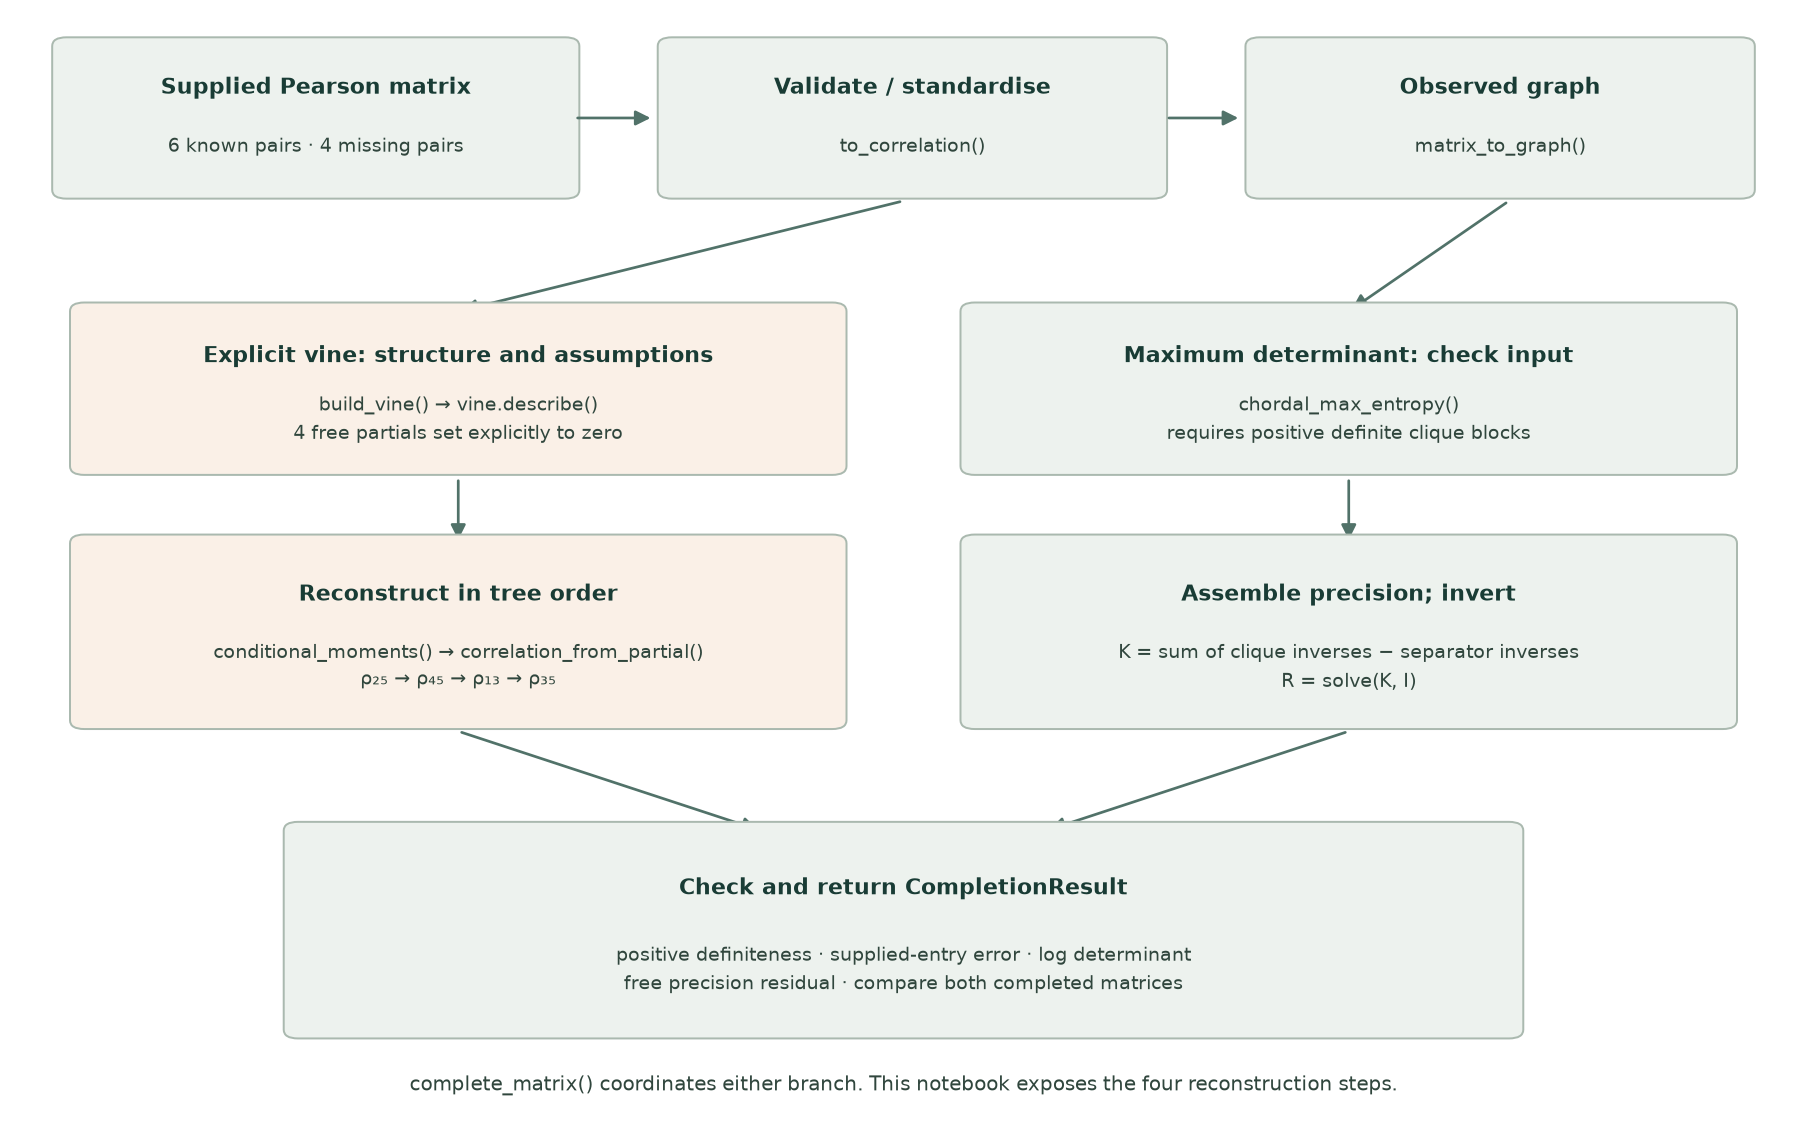

In [2]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def workflow_box(ax, x, y, width, height, title, detail, colour="#edf2ee"):
    """Draw a labelled box only; no matrix calculation."""
    ax.add_patch(FancyBboxPatch((x,y),width,height,boxstyle="round,pad=0.008",
                               facecolor=colour,edgecolor="#aab9af",linewidth=1.1))
    ax.text(x+width/2,y+height*.71,title,ha="center",va="center",fontsize=12,
            weight="bold",color="#193c35")
    ax.text(x+width/2,y+height*.30,detail,ha="center",va="center",fontsize=10.5,
            color="#30463d",linespacing=1.5)

def workflow_arrow(ax, start, end, colour="#517269"):
    """Draw a process arrow only; the code cells determine execution order."""
    ax.add_patch(FancyArrowPatch(start,end,arrowstyle="-|>",mutation_scale=17,
                                 linewidth=1.5,color=colour))

fig,ax=plt.subplots(figsize=(14,8.8))
ax.set(xlim=(0,1),ylim=(0,1)); ax.axis("off")
workflow_box(ax,.03,.84,.28,.13,"Supplied Pearson matrix","6 known pairs · 4 missing pairs")
workflow_box(ax,.37,.84,.27,.13,"Validate / standardise","to_correlation()")
workflow_box(ax,.70,.84,.27,.13,"Observed graph","matrix_to_graph()")
workflow_arrow(ax,(.315,.905),(.36,.905)); workflow_arrow(ax,(.647,.905),(.69,.905))
workflow_arrow(ax,(.50,.83),(.25,.73)); workflow_arrow(ax,(.84,.83),(.75,.73))
workflow_box(ax,.04,.59,.42,.14,"Explicit vine: structure and assumptions",
             "build_vine() → vine.describe()\n4 free partials set explicitly to zero", "#faf0e7")
workflow_box(ax,.54,.59,.42,.14,"Maximum determinant: check input",
             "chordal_max_entropy()\nrequires positive definite clique blocks")
workflow_arrow(ax,(.25,.58),(.25,.52)); workflow_arrow(ax,(.75,.58),(.75,.52))
workflow_box(ax,.04,.36,.42,.16,"Reconstruct in tree order",
             "conditional_moments() → correlation_from_partial()\nρ₂₅ → ρ₄₅ → ρ₁₃ → ρ₃₅", "#faf0e7")
workflow_box(ax,.54,.36,.42,.16,"Assemble precision; invert",
             "K = sum of clique inverses − separator inverses\nR = solve(K, I)")
workflow_arrow(ax,(.25,.35),(.42,.26)); workflow_arrow(ax,(.75,.35),(.58,.26))
workflow_box(ax,.16,.08,.68,.18,"Check and return CompletionResult",
             "positive definiteness · supplied-entry error · log determinant\nfree precision residual · compare both completed matrices")
ax.text(.5,.025,"complete_matrix() coordinates either branch. This notebook exposes the four reconstruction steps.",
        ha="center",fontsize=11,color="#30463d")
fig.tight_layout(); plt.show()


### Function map for the main walkthrough

Variable labels passed to package functions start at **1**; NumPy array indices
start at **0**. `S` is the set of variables removed by linear regression.

| Function | Inputs in this walkthrough | Output | Role |
| --- | --- | --- | --- |
| `matrix_to_graph(R)` | Incomplete Pearson matrix; `NaN` means missing | NetworkX graph with 1-based labels and supplied correlations as weights | Show the information actually supplied; a known zero is still an edge. |
| `build_vine(R, strategy="greedy")` | Incomplete `R` and structure rule | `Vine`, containing four trees | Choose a valid sequence of pair/conditioning-set coordinates. It does not fill the matrix. |
| `vine.describe(R)` | The chosen vine and incomplete `R` | One record per edge: tree, pair, conditioning set, observed/free status and calculable partial | Separate what is known from what must be assumed. `None` means unavailable, not zero. |
| `conditional_moments(working, x, y, S)` | Matrix as filled so far; pair and conditioning set | `(b, v_x, v_y)` | Calculate the regression contribution and two residual variances needed for the next entry. |
| `correlation_from_partial(working, x, y, S, p)` | The same inputs plus chosen partial `p` | One ordinary correlation | Evaluate `b + p*sqrt(v_x*v_y)`. The caller writes it symmetrically into the matrix. |
| `partial_corr(working, x, y, S)` | An available ordinary pair and its required block | One implied partial correlation | Convert supplied ordinary information into a vine coordinate; it does not choose a free assumption. |
| `complete_matrix(R, ...)` | Input matrix, policy, structure and explicit partial records | `CompletionResult` | Run completion, preserve observations and check the result. We compare it with the exposed arithmetic. |

`edge_key(pair, S)` formats labels, for example `"2,5.1"` for
$\rho_{25\cdot1}$. It has no numerical effect. The supporting-function reference
at the end covers validation, the chordal solver and output fields.


## 3. Specify the information

`np.nan` marks an unknown entry. A supplied zero would remain a fixed observation.
Missing entries must be symmetric; the diagonal is one.

These are the explorer's **rounded GIRO inputs**. D10 rounds the displayed
figures further; the computation below retains every supplied decimal.
The original full-precision covariance example is separate, at the end.


In [3]:
R = np.array([
    [1,     -.586, np.nan,  .309, -.374],
    [-.586, 1,      .540,  -.785, np.nan],
    [np.nan, .540,  1,     -.059, np.nan],
    [.309, -.785,  -.059,   1,    np.nan],
    [-.374, np.nan, np.nan, np.nan, 1],
])
observed = np.isfinite(R)
missing_pairs = [(i, j) for i in range(len(R)) for j in range(i + 1, len(R)) if not observed[i, j]]
print("Incomplete Pearson correlation matrix (nan = unknown):")
print(R)
pair_count = len(R) * (len(R) - 1) // 2
print(f"\n{len(R)} variables; {pair_count - len(missing_pairs)} supplied pairs; {len(missing_pairs)} missing pairs.")


Incomplete Pearson correlation matrix (nan = unknown):
[[ 1.    -0.586    nan  0.309 -0.374]
 [-0.586  1.     0.54  -0.785    nan]
 [   nan  0.54   1.    -0.059    nan]
 [ 0.309 -0.785 -0.059  1.       nan]
 [-0.374    nan    nan    nan  1.   ]]

5 variables; 6 supplied pairs; 4 missing pairs.


Observed graph is chordal: True


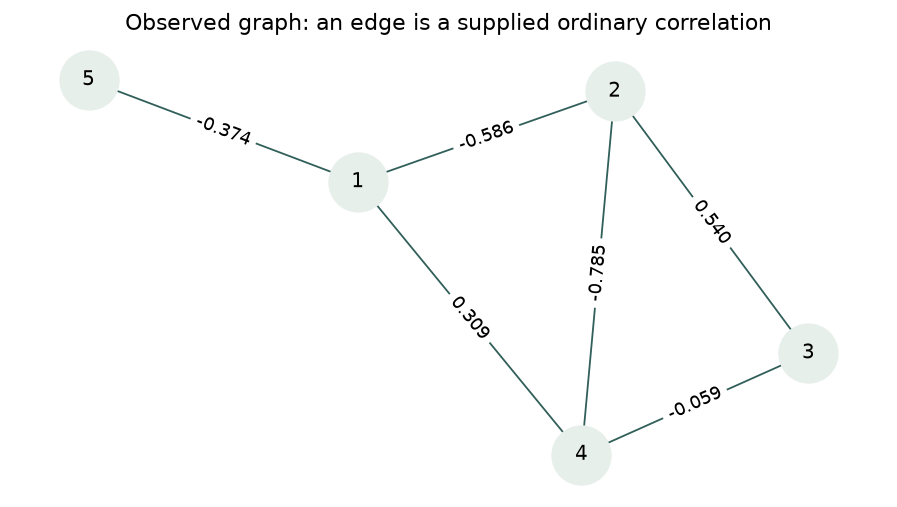

In [4]:
graph = matrix_to_graph(R)
print("Observed graph is chordal:", nx.is_chordal(graph))

fig, ax = plt.subplots(figsize=(7, 4))
pos = nx.spring_layout(graph, seed=7, weight=None)
nx.draw_networkx(graph, pos, ax=ax, node_color="#e7efeb", node_size=1050,
                 edge_color="#315f59", font_size=11)
nx.draw_networkx_edge_labels(graph, pos, ax=ax,
    edge_labels={(u, v): f"{d['weight']:.3f}" for u, v, d in graph.edges(data=True)}, font_size=10)
ax.set_title("Observed graph: an edge is a supplied ordinary correlation")
ax.set_axis_off()
fig.tight_layout()
plt.show()


## 4. Inspect the vine and state the free partials

The package's deterministic greedy rule prioritises edges whose partial correlations
can be calculated from supplied information, then absolute strength. This is one
choice of vine structure. The package checks spanning trees and the regular-vine
proximity condition.

A dot denotes partial correlation, for example $\rho_{25\cdot1}$.
The four orange edges below are additional choices, not supplied observations.


In [5]:
vine = build_vine(R, strategy="greedy")
plan = vine.describe(R)
print("Tree  Partial coordinate     From supplied information")
for row in plan:
    value = row["partial_from_observations"]
    shown = "free" if value is None else f"{value:.6f}"
    print(f"{row['tree']:>4}  {row['key']:<22} {shown}")

free_partials = [
    {"conditioned": row["conditioned"], "conditioning": row["conditioning"], "value": 0.0}
    for row in plan if not row["observed_pair"]
]
assert len(free_partials) == 4
print("\nExplicit assumptions for this worked example:")
for item in free_partials:
    print(edge_key(item["conditioned"], item["conditioning"]), "=", item["value"])


Tree  Partial coordinate     From supplied information
   1  1,2                    -0.586000
   1  1,5                    -0.374000
   1  2,4                    -0.785000
   1  2,3                    0.540000
   2  1,4.2                  -0.300826
   2  2,5.1                  free
   2  3,4.2                  0.699836
   3  4,5.1,2                free
   3  1,3.2,4                free
   4  3,5.1,2,4              free

Explicit assumptions for this worked example:
2,5.1 = 0.0
4,5.1,2 = 0.0
1,3.2,4 = 0.0
3,5.1,2,4 = 0.0


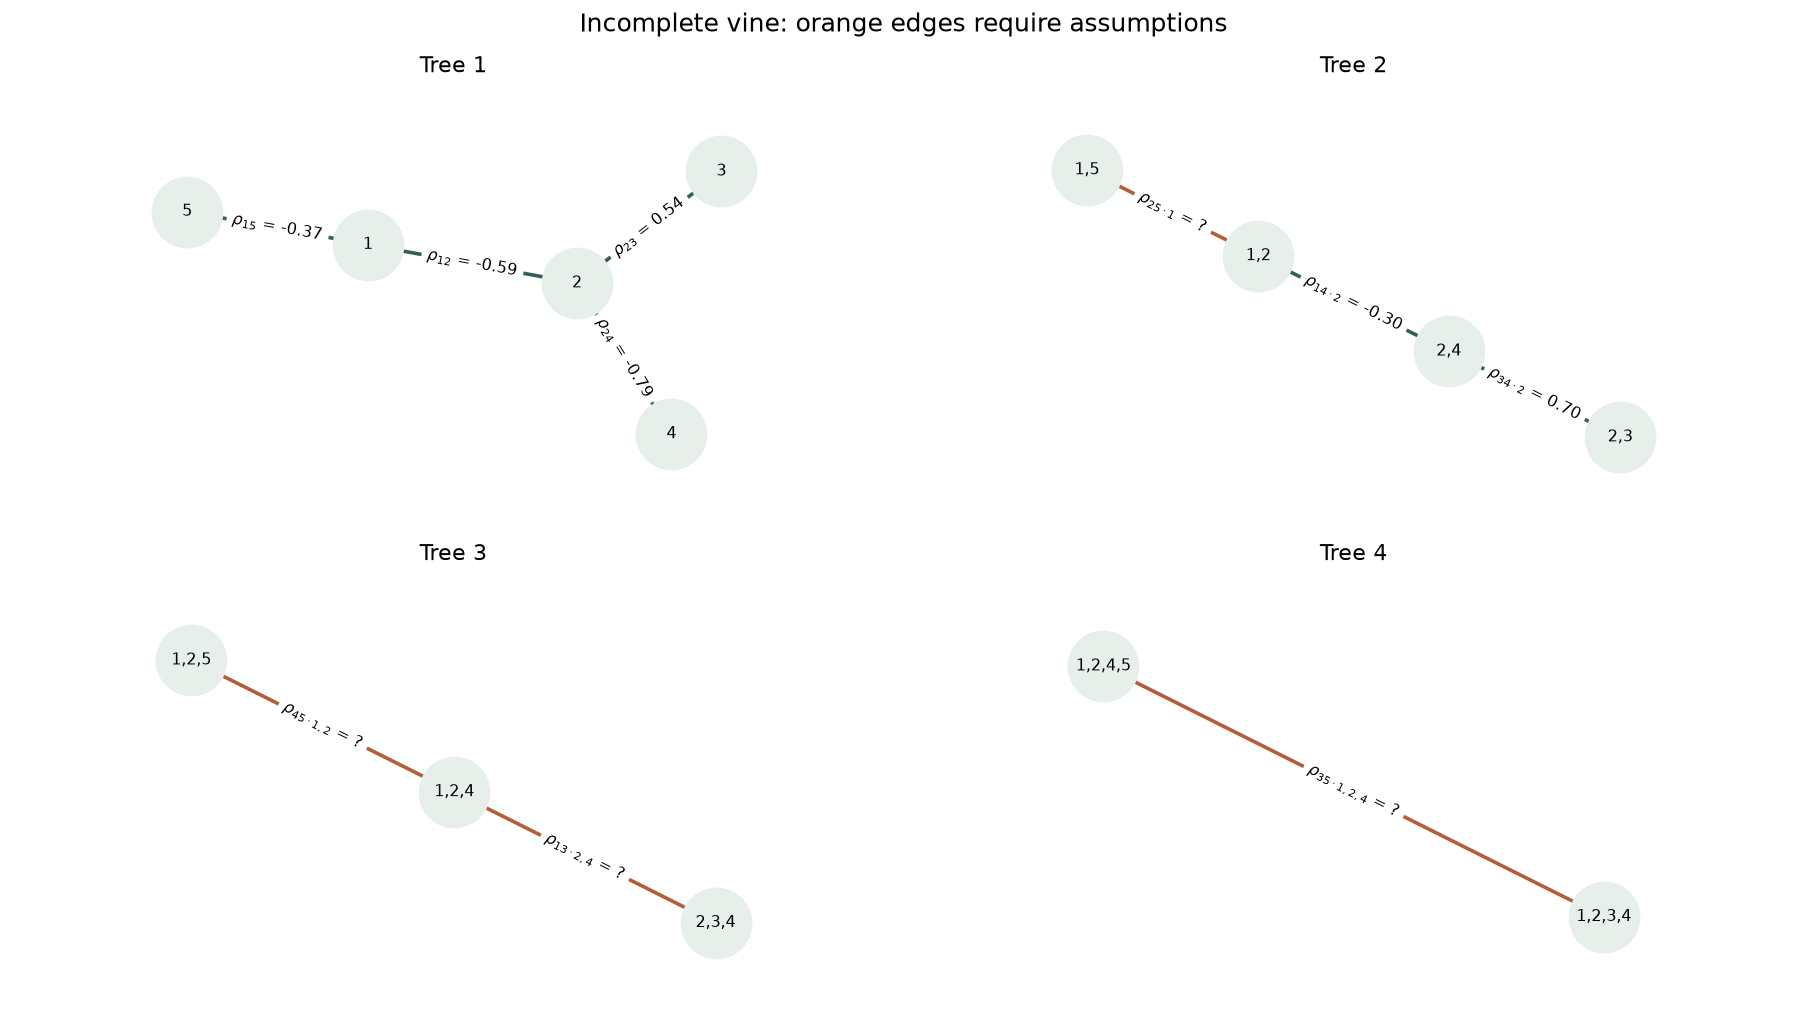

In [6]:
def partial_label(pair, conditioning):
    suffix = r"\cdot" + ",".join(map(str, conditioning)) if conditioning else ""
    return r"$\rho_{" + "".join(map(str, pair)) + suffix + "}$"

lookup = {row["key"]: row["partial_from_observations"] for row in plan}
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for level, (tree, ax) in enumerate(zip(vine.trees, axes.flat), 1):
    positions = nx.spring_layout(tree, seed=7, weight=None)
    labels = {node: ",".join(map(str, sorted(data["variables"]))) for node, data in tree.nodes(data=True)}
    nx.draw_networkx_nodes(tree, positions, ax=ax, node_color="#e7efeb", node_size=1500)
    nx.draw_networkx_labels(tree, positions, labels=labels, ax=ax, font_size=9)
    edge_labels = {}
    for u, v, data in tree.edges(data=True):
        key = edge_key(data["conditioned"], data["conditioning"])
        value = lookup[key]
        colour = "#b45e38" if value is None else "#315f59"
        nx.draw_networkx_edges(tree, positions, edgelist=[(u, v)], ax=ax, edge_color=colour, width=2)
        edge_labels[(u, v)] = partial_label(data["conditioned"], data["conditioning"]) + (
            " = ?" if value is None else f" = {value:.2f}")
    nx.draw_networkx_edge_labels(tree, positions, edge_labels=edge_labels, ax=ax, font_size=9)
    ax.set_title(f"Tree {level}")
    ax.margins(0.30)
    ax.set_axis_off()
fig.suptitle("Incomplete vine: orange edges require assumptions", fontsize=14)
fig.tight_layout()
plt.show()


The six supplied **ordinary** correlations are constraints. At higher vine levels,
their partial correlations are calculated from available blocks. For example,
$\rho_{14\cdot2}$ is implied by supplied $\rho_{14},\rho_{12},\rho_{24}$;
it is not an additional input. A higher-level observed pair may need earlier filled
entries before its partial can be evaluated.

The four free coordinates here are $\rho_{25\cdot1}$,
$\rho_{45\cdot1,2}$, $\rho_{13\cdot2,4}$ and $\rho_{35\cdot1,2,4}$.
We deliberately supply **0** for each. These are correlations of regression
residuals; no claim of general conditional independence is being made.


## 5. Reconstruct all four missing correlations

For a pair $x,y$ and conditioning set $S$, the same block calculation is used each time:

$$b=R_{xS}R_{SS}^{-1}R_{Sy},\quad
v_x=1-R_{xS}R_{SS}^{-1}R_{Sx},\quad
v_y=1-R_{yS}R_{SS}^{-1}R_{Sy},$$
$$\boxed{\rho_{xy}=b+\rho_{xy\cdot S}\sqrt{v_xv_y}}.$$

`conditional_moments()` returns **b**, the contribution carried through `S`, and
the two **residual variances**. For ordinary Pearson input these are linear-regression quantities.
Interpreting them as general conditional-distribution quantities requires further assumptions.
`correlation_from_partial()` adds the chosen residual association. It solves the
small linear system rather than explicitly forming an inverse. For an empty conditioning set, `conditional_moments()` returns `(0, 1, 1)`, so a first-tree partial correlation equals its ordinary correlation.

With the chosen partial zero, the added term is zero, so the new correlation equals
`b`. It need not be zero. The residual variances still matter: they must be positive
for the calculation to be valid. Only finite lower-order entries may be used.


In [7]:
# Expose the same calculation order as the package, without changing the supplied R.
working = R.copy()
reconstruction = []
expected_order = [(level, edge_key(data["conditioned"], data["conditioning"]))
                  for level, data in vine.edges()
                  if not observed[data["conditioned"][0]-1, data["conditioned"][1]-1]]
assert expected_order == [(2,"2,5.1"),(3,"4,5.1,2"),(3,"1,3.2,4"),(4,"3,5.1,2,4")]
print("Missing-pair order:", expected_order)


Missing-pair order: [(2, '2,5.1'), (3, '4,5.1,2'), (3, '1,3.2,4'), (4, '3,5.1,2,4')]


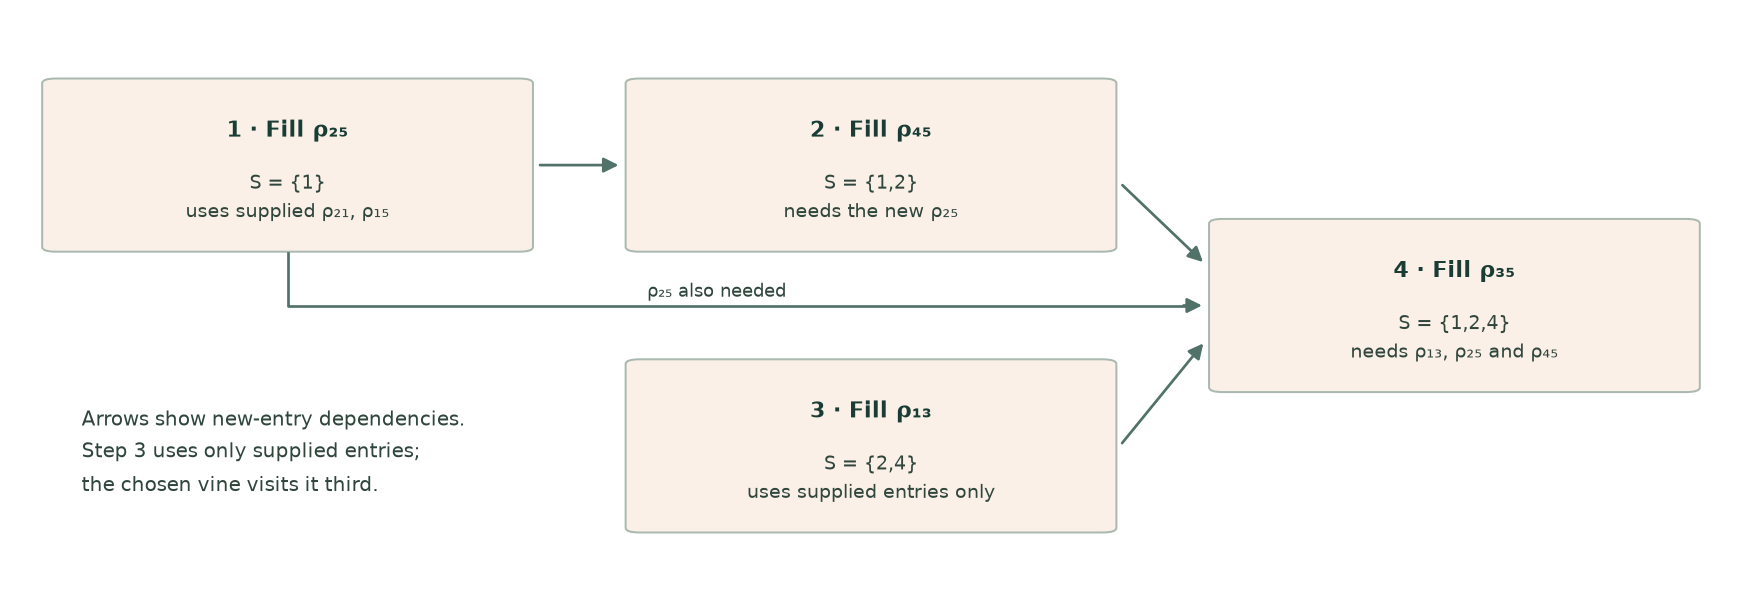

In [8]:
fig,ax=plt.subplots(figsize=(13.5,4.8)); ax.set(xlim=(0,1),ylim=(0,1)); ax.axis("off")
workflow_box(ax,.025,.60,.27,.28,"1 · Fill ρ₂₅","S = {1}\nuses supplied ρ₂₁, ρ₁₅", "#faf0e7")
workflow_box(ax,.365,.60,.27,.28,"2 · Fill ρ₄₅","S = {1,2}\nneeds the new ρ₂₅", "#faf0e7")
workflow_box(ax,.365,.12,.27,.28,"3 · Fill ρ₁₃","S = {2,4}\nuses supplied entries only", "#faf0e7")
workflow_box(ax,.705,.36,.27,.28,"4 · Fill ρ₃₅","S = {1,2,4}\nneeds ρ₁₃, ρ₂₅ and ρ₄₅", "#faf0e7")
workflow_arrow(ax,(.305,.74),(.355,.74))
ax.plot([.16,.16,.685],[.59,.50,.50],color="#517269",linewidth=1.5)
workflow_arrow(ax,(.68,.50),(.695,.50))
ax.text(.41,.515,"ρ₂₅ also needed",ha="center",fontsize=10,color="#30463d")
workflow_arrow(ax,(.645,.71),(.695,.57))
workflow_arrow(ax,(.645,.26),(.695,.44))
ax.text(.04,.25,"Arrows show new-entry dependencies.\nStep 3 uses only supplied entries;\nthe chosen vine visits it third.",
        fontsize=11,color="#30463d",va="center",linespacing=1.6)
fig.tight_layout(); plt.show()


### Step 1: fill $\rho_{25}$ using $\rho_{25\cdot1}=0$

The one-variable block is $R_{11}=1$. The contribution is
$(-0.586)(-0.374)=0.219164$. This uses supplied entries only.


In [9]:
x, y, S = 2, 5, (1,)
p = 0.0  # the explicit partial-correlation assumption for this edge
b, vx, vy = conditional_moments(working, x, y, S)
value = correlation_from_partial(working, x, y, S, p)

# This line is explanatory arithmetic: the shared package function above supplies value.
s = [label - 1 for label in S]
weights = np.linalg.solve(working[np.ix_(s, s)], working[s, y-1])
print("Linear-system weights:", weights)
print(f"b = {b:.9f}; residual variances = ({vx:.9f}, {vy:.9f})")
print(f"rho_{x}{y} = {b:.9f} + {p:.1f} × {np.sqrt(vx*vy):.9f} = {value:.9f}")
assert np.isclose(value, b + p*np.sqrt(vx*vy), atol=1e-12, rtol=0)
working[x-1,y-1] = working[y-1,x-1] = value
reconstruction.append({"pair":(x,y), "conditioning":S, "partial":p,
                       "b":b, "vx":vx, "vy":vy, "value":value})


Linear-system weights: [-0.374]
b = 0.219164000; residual variances = (0.656604000, 0.860124000)
rho_25 = 0.219164000 + 0.0 × 0.751505728 = 0.219164000


### Step 2: fill $\rho_{45}$ using $\rho_{45\cdot1,2}=0$

Now use $S=\{1,2\}$ and the newly filled $\rho_{25}$:

$$R_{SS}=\begin{pmatrix}1&-0.586\\-0.586&1\end{pmatrix},\quad
R_{4S}=(0.309,-0.785),\quad R_{S5}=(-0.374,0.219164)^\mathsf{T}.$$

Solving $R_{SS}w=R_{S5}$ gives $w=(-0.374,0)^\mathsf{T}$ to rounding.
Thus $b=(0.309)(-0.374)+(-0.785)(0)=-0.115566$.


In [10]:
x, y, S = 4, 5, (1, 2)
p = 0.0  # the explicit partial-correlation assumption for this edge
b, vx, vy = conditional_moments(working, x, y, S)
value = correlation_from_partial(working, x, y, S, p)

# This line is explanatory arithmetic: the shared package function above supplies value.
s = [label - 1 for label in S]
weights = np.linalg.solve(working[np.ix_(s, s)], working[s, y-1])
print("Linear-system weights:", weights)
print(f"b = {b:.9f}; residual variances = ({vx:.9f}, {vy:.9f})")
print(f"rho_{x}{y} = {b:.9f} + {p:.1f} × {np.sqrt(vx*vy):.9f} = {value:.9f}")
assert np.isclose(value, b + p*np.sqrt(vx*vy), atol=1e-12, rtol=0)
working[x-1,y-1] = working[y-1,x-1] = value
reconstruction.append({"pair":(x,y), "conditioning":S, "partial":p,
                       "b":b, "vx":vx, "vy":vy, "value":value})


Linear-system weights: [-0.374  0.   ]
b = -0.115566000; residual variances = (0.349044751, 0.860124000)
rho_45 = -0.115566000 + 0.0 × 0.547924966 = -0.115566000


### Step 3: fill $\rho_{13}$ using $\rho_{13\cdot2,4}=0$

This gap uses supplied entries only:

$$R_{SS}=\begin{pmatrix}1&-0.785\\-0.785&1\end{pmatrix},\quad
R_{1S}=(-0.586,0.309),\quad R_{S3}=(0.540,-0.059)^\mathsf{T}.$$

The printed linear-system weights below give
$b=R_{1S}\,\operatorname{solve}(R_{SS},R_{S3})=-0.460022956\ldots$.
This step removes the linear effects of two variables, so multiplying two ordinary
correlations would not give the required contribution.


In [11]:
x, y, S = 1, 3, (2, 4)
p = 0.0  # the explicit partial-correlation assumption for this edge
b, vx, vy = conditional_moments(working, x, y, S)
value = correlation_from_partial(working, x, y, S, p)

# This line is explanatory arithmetic: the shared package function above supplies value.
s = [label - 1 for label in S]
weights = np.linalg.solve(working[np.ix_(s, s)], working[s, y-1])
print("Linear-system weights:", weights)
print(f"b = {b:.9f}; residual variances = ({vx:.9f}, {vy:.9f})")
print(f"rho_{x}{y} = {b:.9f} + {p:.1f} × {np.sqrt(vx*vy):.9f} = {value:.9f}")
assert np.isclose(value, b + p*np.sqrt(vx*vy), atol=1e-12, rtol=0)
working[x-1,y-1] = working[y-1,x-1] = value
reconstruction.append({"pair":(x,y), "conditioning":S, "partial":p,
                       "b":b, "vx":vx, "vy":vy, "value":value})


Linear-system weights: [1.286392 0.950818]
b = -0.460022956; residual variances = (0.597183714, 0.361446681)
rho_13 = -0.460022956 + 0.0 × 0.464596676 = -0.460022956


### Step 4: fill $\rho_{35}$ using $\rho_{35\cdot1,2,4}=0$

This step needs all three earlier filled entries:

$$R_{SS}=\begin{pmatrix}1&-0.586&0.309\\-0.586&1&-0.785\\0.309&-0.785&1\end{pmatrix},$$
$$R_{3S}=(\rho_{13},0.540,-0.059),\quad
R_{S5}=(-0.374,\rho_{25},\rho_{45})^\mathsf{T}.$$

Here the weights are $(-0.374,0,0)^\mathsf{T}$ to rounding, giving
$b=(-0.460022956\ldots)(-0.374)=0.172048586\ldots$.
The unrounded earlier results are used in the code.


In [12]:
x, y, S = 3, 5, (1, 2, 4)
p = 0.0  # the explicit partial-correlation assumption for this edge
b, vx, vy = conditional_moments(working, x, y, S)
value = correlation_from_partial(working, x, y, S, p)

# This line is explanatory arithmetic: the shared package function above supplies value.
s = [label - 1 for label in S]
weights = np.linalg.solve(working[np.ix_(s, s)], working[s, y-1])
print("Linear-system weights:", weights)
print(f"b = {b:.9f}; residual variances = ({vx:.9f}, {vy:.9f})")
print(f"rho_{x}{y} = {b:.9f} + {p:.1f} × {np.sqrt(vx*vy):.9f} = {value:.9f}")
assert np.isclose(value, b + p*np.sqrt(vx*vy), atol=1e-12, rtol=0)
working[x-1,y-1] = working[y-1,x-1] = value
reconstruction.append({"pair":(x,y), "conditioning":S, "partial":p,
                       "b":b, "vx":vx, "vy":vy, "value":value})


Linear-system weights: [-0.374  0.     0.   ]
b = 0.172048586; residual variances = (0.361446681, 0.860124000)
rho_35 = 0.172048586 + 0.0 × 0.557574179 = 0.172048586


### The four results together

Each row below is the actual output of the corresponding package call above.
The conditioning sets and zero partials are assumptions used in this calculation;
the completed ordinary correlations are its outputs.


In [13]:
print("Pair   S          chosen partial   b           sqrt(vx*vy)  filled correlation")
for step in reconstruction:
    pair = "".join(map(str, step["pair"]))
    s = ",".join(map(str, step["conditioning"]))
    print(f"{pair:<6} {s:<10} {step['partial']:>7.1f}      {step['b']:>11.9f}  "
          f"{np.sqrt(step['vx']*step['vy']):>11.9f}   {step['value']:>11.9f}")
assert np.array_equal(working[observed], R[observed])
assert np.isfinite(working).all()


Pair   S          chosen partial   b           sqrt(vx*vy)  filled correlation
25     1              0.0      0.219164000  0.751505728   0.219164000
45     1,2            0.0      -0.115566000  0.547924966   -0.115566000
13     2,4            0.0      -0.460022956  0.464596676   -0.460022956
35     1,2,4          0.0      0.172048586  0.557574179   0.172048586


## 6. Run the coordinated function and inspect its return value

`complete_matrix()` starts from the **original incomplete** matrix. In `vine` mode,
it visits all ten edges in tree order: supplied ordinary pairs are kept fixed and
their implied partials evaluated; missing pairs are reconstructed using our four
partial records. `missing="error"` requires every free assumption to be present.

It then checks the matrix and returns a `CompletionResult`:

| Field | Meaning here |
| --- | --- |
| `result.correlation` | Completed Pearson matrix `R`. |
| `result.matrix` | Completed matrix on the input scale; the same as `correlation` here. Covariance input is restored to its original units. |
| `result.vine` | Chosen trees and their calculated partial correlations. |
| `result.edges` | All ten edge records: tree, pair, conditioning set, ordinary/partial values and source. |
| `result.diagnostics` | Validity, preservation and numerical maximum-determinant checks. |
| `result.to_dict()` | The same result as a JSON-compatible dictionary for saving or integration. |

The equality check below ties every exposed step back to the production function.


In [14]:
result = complete_matrix(R, kind="correlation", method="vine", strategy="greedy",
                         partials=free_partials, missing="error")
print("Completed Pearson correlation matrix:")
print(result.correlation)
print("\nInferred pairs:")
for i, j in missing_pairs:
    print(f"rho_{i + 1}{j + 1} = {result.correlation[i, j]:.6f}")


Completed Pearson correlation matrix:
[[ 1.       -0.586    -0.460023  0.309    -0.374   ]
 [-0.586     1.        0.54     -0.785     0.219164]
 [-0.460023  0.54      1.       -0.059     0.172049]
 [ 0.309    -0.785    -0.059     1.       -0.115566]
 [-0.374     0.219164  0.172049 -0.115566  1.      ]]

Inferred pairs:
rho_13 = -0.460023
rho_25 = 0.219164
rho_35 = 0.172049
rho_45 = -0.115566


In [15]:
trace_agreement = float(np.max(np.abs(working - result.correlation)))
assert trace_agreement < 1e-12
assert [(row["tree"],row["key"]) for row in result.edges if row["source"]=="supplied"] == expected_order
print(f"Four-step trace versus complete_matrix(): maximum difference {trace_agreement:.3g}")
print("All ten vine edges (observed = supplied ordinary pair; supplied = chosen partial):")
for row in result.edges:
    print(f"T{row['tree']}  {row['key']:<12}  partial={row['partial_correlation']: .6f}  "
          f"ordinary={row['ordinary_correlation']: .6f}  {row['source']}")


Four-step trace versus complete_matrix(): maximum difference 0
All ten vine edges (observed = supplied ordinary pair; supplied = chosen partial):
T1  1,2           partial=-0.586000  ordinary=-0.586000  observed
T1  1,5           partial=-0.374000  ordinary=-0.374000  observed
T1  2,4           partial=-0.785000  ordinary=-0.785000  observed
T1  2,3           partial= 0.540000  ordinary= 0.540000  observed
T2  1,4.2         partial=-0.300826  ordinary= 0.309000  observed
T2  2,5.1         partial= 0.000000  ordinary= 0.219164  supplied
T2  3,4.2         partial= 0.699836  ordinary=-0.059000  observed
T3  4,5.1,2       partial= 0.000000  ordinary=-0.115566  supplied
T3  1,3.2,4       partial= 0.000000  ordinary=-0.460023  supplied
T4  3,5.1,2,4     partial= 0.000000  ordinary= 0.172049  supplied


## 7. Read the numerical checks

| Check | What to look for | Meaning |
| --- | --- | --- |
| Minimum eigenvalue | Above the package tolerance `1e-10` | The matrix is strictly positive definite at this tolerance. A failure means the chosen completion is unusable here. |
| Supplied-entry error | Zero here; errors above `10*tol` (`1e-9` here) are rejected | The input constraints have been preserved. A different number in a missing position is permitted. |
| `log det(R)` | Compare only with the same input constraints and scale | The objective value. Its sign alone is not a pass/fail check. |
| Free precision residual | Largest absolute entry of `R⁻¹` at originally missing positions; at most `1e-8` here | Together with feasibility, supports the maximum-log-determinant certificate under the original observed constraints. |
| Agreement with chordal policy | Below `1e-12` here | A separate production route gives the same completed matrix for this example. |

These are numerical checks of the stated matrix problem. They do not establish
empirical recovery, tail dependence or suitability for a capital model.


In [16]:
maximum_determinant = complete_matrix(R, kind="correlation", method="max_entropy")
agreement = float(np.max(np.abs(result.correlation - maximum_determinant.correlation)))
d = result.diagnostics
print(f"Minimum eigenvalue:       {d['minimum_eigenvalue_correlation']:.9f}")
print(f"Supplied-entry error:     {d['maximum_observed_error_correlation']:.3g}")
print(f"log det(R):               {d['log_determinant_correlation']:.9f}")
print(f"det(R):                   {np.linalg.det(result.correlation):.9f}")
print(f"Free precision residual:  {d['free_precision_max_abs']:.3g}")
print(f"Chordal-policy agreement: {agreement:.3g}")
print("Maximum determinant certified:", d["max_entropy_certified"])

assert np.array_equal(result.correlation[observed], R[observed])
assert d["minimum_eigenvalue_correlation"] > 1e-10
assert d["max_entropy_certified"]
assert agreement < 1e-12


Minimum eigenvalue:       0.066817176
Supplied-entry error:     0
log det(R):               -2.641548775
det(R):                   0.071250833
Free precision residual:  1.02e-15
Chordal-policy agreement: 1.94e-16
Maximum determinant certified: True


The free-position entries of $R^{-1}$ are numerically zero. Together with positive
definiteness and preserved observations, this is the stationarity certificate for
maximum log determinant under the **original observed-entry constraints**.
It is separate from the feasibility checks and does not certify a different
optimisation problem with additional partial-correlation constraints.

With a multivariate Gaussian model and fixed variances, maximum determinant also
maximises differential entropy. Gaussianity is an additional model assumption.


## 8. How the separate maximum-determinant branch works

`complete_matrix(method="max_entropy")` calls `chordal_max_entropy()` rather than
guessing zero values on an arbitrary vine. It requires a chordal observed graph
and positive definite specified maximal cliques. The completed matrix is then expressed on the selected vine. Changing that representation does not change the maximum-determinant optimum.

For this five-variable graph, the maximal cliques are `{1,2,4}`, `{1,5}` and
`{2,3,4}`. One valid clique tree joins them through separators `{1}` and `{2,4}`.
The package adds embedded clique inverses and subtracts separator inverses:

$$K=\operatorname{embed}(R_{124}^{-1})+
\operatorname{embed}(R_{15}^{-1})+\operatorname{embed}(R_{234}^{-1})
-\operatorname{embed}(R_{1}^{-1})-\operatorname{embed}(R_{24}^{-1}),\qquad R^*=K^{-1}.$$

“Embed” means placing a small inverse block into the matching rows and columns of
a five-by-five zero matrix. The optional arithmetic below exposes that calculation
for this example and checks it against the package helper. Production callers use
`complete_matrix()`; they do not need to copy the assembly code.


In [17]:
cliques = [(1,2,4), (1,5), (2,3,4)]
separators = [(1,), (2,4)]
assert set(cliques) == {tuple(sorted(c)) for c in nx.find_cliques(graph)}
K = np.zeros_like(R)
for sign, groups in ((1,cliques),(-1,separators)):
    for labels in groups:
        indices = [label-1 for label in labels]
        block = R[np.ix_(indices,indices)]
        K[np.ix_(indices,indices)] += sign*np.linalg.solve(block,np.eye(len(indices)))

clique_arithmetic = np.linalg.solve(K,np.eye(len(R)))
chordal_result = chordal_max_entropy(R)
clique_agreement = float(np.max(np.abs(clique_arithmetic - chordal_result)))
assert clique_agreement < 1e-12
assert np.allclose(chordal_result, result.correlation, atol=1e-12, rtol=0)
print("Assembled precision K (zeros at the four free pairs):")
print(K)
print(f"Clique arithmetic versus chordal_max_entropy(): {clique_agreement:.3g}")


Assembled precision K (zeros at the four free pairs):
[[ 1.83715   1.498511  0.        0.658902  0.434821]
 [ 1.498511  8.524969 -3.559008  6.01908   0.      ]
 [ 0.       -3.559008  2.76666  -2.630589  0.      ]
 [ 0.658902  6.01908  -2.630589  5.366172  0.      ]
 [ 0.434821  0.        0.        0.        1.162623]]
Clique arithmetic versus chordal_max_entropy(): 1.33e-15


## 9. Separate a modelling choice from the completion objective

For three variables, two ordinary correlations of 0.5 leave one gap.
Maximum determinant gives 0.25. Supplying the partial correlation
$\rho_{13\cdot2}=0.4$ instead gives $\rho_{13}=0.55$.
The extra partial-correlation assumption changes the question being answered.


In [18]:
three = np.array([[1, .5, np.nan], [.5, 1, .5], [np.nan, .5, 1]])
baseline = complete_matrix(three, method="max_entropy")
alternative = complete_matrix(three, method="vine", strategy="d-vine", order=[1, 2, 3],
    partials=[{"conditioned": [1, 3], "conditioning": [2], "value": .4}], missing="error")
print(f"Maximum determinant, with only the two observations: rho_13 = {baseline.correlation[0, 2]:.2f}")
print(f"Explicit partial rho_13·2 = 0.4:                     rho_13 = {alternative.correlation[0, 2]:.2f}")
assert np.isclose(baseline.correlation[0, 2], .25)
assert np.isclose(alternative.correlation[0, 2], .55)


Maximum determinant, with only the two observations: rho_13 = 0.25
Explicit partial rho_13·2 = 0.4:                     rho_13 = 0.55


## Reference: the supporting functions and libraries

This reference covers the calculation functions reached by the walkthrough, including
those called inside `complete_matrix()`. Readers reusing the package normally start
with that coordinating function.

| Function / method | Inputs → outputs | Purpose and limits |
| --- | --- | --- |
| `validate_matrix(matrix, kind, tol)` | Input array, scale and tolerance → independent float array | Check square shape, symmetry, missingness, diagonal and correlation range. It does not fill gaps or prove a completion exists. |
| `to_correlation(matrix, kind, tol)` | Correlation or covariance input → `(R, standard_deviations)` | Call validation; divide covariance by the standard-deviation outer product. The deviations later restore covariance units. |
| `Vine.edges()` | A `Vine` → iterator of `(tree_level, edge_data)` | Supply the tree order and each conditioned pair / conditioning set to reconstruction. |
| `chordal_max_entropy(R, tol)` | Incomplete Pearson `R` → completed `R` | Check graph/cliques, assemble clique-minus-separator precision and invert. Reject unsupported nonchordal input. |
| `require_positive_definite(R, tol, context)` | Finite square matrix and tolerance → smallest eigenvalue, or error | Reject missing entries, singularity, indefiniteness and matrices too close to singular at the tolerance. |
| `CompletionResult.to_dict()` | Result object → dictionary of lists, edge records and diagnostics | Export calculated information; no further completion. |
| `np.linalg.solve(A, B)` | Square nonsingular `A`, right side `B` → solution `X` of `AX=B` | Compute regression weights or inverse blocks (when `B=I`) without explicitly calling `inv`. |
| `nx.is_chordal(graph)` | Observed graph → Boolean | Test whether every cycle of length ≥4 has a chord; this governs support for the default chordal policy. |
| `np.linalg.eigvalsh(R)`, `slogdet(R)` | Completed symmetric matrix → eigenvalues, or determinant sign/log magnitude | Supply validity and objective diagnostics; the package reports the minimum eigenvalue and log determinant. |

**Internal helpers, for readers following the source:** `_indices(matrix,x,y,S)`
checks distinct 1-based labels and returns zero-based indices; `_normalize_partials(partials,vine)`
validates partial records and returns an edge-key/value dictionary; `_add_edge(graph,u,v)`
adds the conditioned pair (symmetric difference) and conditioning set (intersection) to a candidate edge;
`_next_candidates(tree)` returns the next-level candidate graph by joining previous
edges that share a node. The nested `add_inverse(labels,sign)` in the chordal helper
adds a checked inverse block to `K` and returns no value.

**Diagram helpers:** `workflow_box()` and `workflow_arrow()` add labelled shapes
to Matplotlib axes and return no calculation result. `partial_label()` returns a
typeset partial-correlation label. NetworkX drawing/layout and Matplotlib figure
calls control presentation only. NumPy array, mask, indexing and comparison calls
prepare or check the displayed data; they do not select the free partial assumptions.

Source: [completion](https://github.com/Xinbin1011/vine-matrix-completion/blob/main/src/vine_completion/completion.py),
[partials](https://github.com/Xinbin1011/vine-matrix-completion/blob/main/src/vine_completion/partials.py),
[vines](https://github.com/Xinbin1011/vine-matrix-completion/blob/main/src/vine_completion/vines.py),
[matrix validation](https://github.com/Xinbin1011/vine-matrix-completion/blob/main/src/vine_completion/matrix.py),
[graphs / chordal policy](https://github.com/Xinbin1011/vine-matrix-completion/blob/main/src/vine_completion/graphs.py).


## Optional: the original full-precision covariance example

The repository's `five_by_five.json` example retains the original covariance
units and full-precision standardisation. It is a distinct preset from the
rounded GIRO inputs above. Small numerical differences are expected.


In [19]:
example = json.loads((repo_root / "examples" / "five_by_five.json").read_text(encoding="utf-8"))
covariance_result = complete_matrix(example["matrix"], kind="covariance", method="max_entropy")
original_covariance = np.asarray(example["matrix"], dtype=float)
covariance_missing_pairs = [(i, j) for i in range(len(original_covariance))
    for j in range(i + 1, len(original_covariance)) if not np.isfinite(original_covariance[i, j])]
print("Completed covariance matrix (original units):")
print(covariance_result.matrix)
print("\nThe four previously missing covariances:")
for i, j in covariance_missing_pairs:
    print(f"M_{i + 1}{j + 1} = {covariance_result.matrix[i, j]:.6f}")


Completed covariance matrix (original units):
[[ 35.       -25.       -16.777963  10.       -15.      ]
 [-25.        52.        24.       -31.        10.714286]
 [-16.777963  24.        38.        -2.         7.190556]
 [ 10.       -31.        -2.        30.        -4.285714]
 [-15.        10.714286   7.190556  -4.285714  46.      ]]

The four previously missing covariances:
M_13 = -16.777963
M_25 = 10.714286
M_35 = 7.190556
M_45 = -4.285714


## Scope and resources

- The default exact maximum-determinant policy supports **chordal** observation
  graphs with positive definite specified cliques. General nonchordal optimisation
  and singular positive semidefinite completions are not implemented.
- Explicit-vine choices can be incompatible. A rejected choice does not prove
  that the original partially specified matrix has no feasible completion.
- A correlation matrix does not identify margins, a copula family, tail dependence
  or a direction of capital change. This is not an empirical insurance calibration.
- A partial correlation describes regression residuals. It is not generally a
  correlation conditional on fixed values of the other variables.

**Use the [demo](https://xinbin1011.github.io/vine-matrix-completion/) to change
inputs and assumptions, the [D10 slides](../docs/resources/GIRO_2026_D10_slides.pdf)
for the conference walkthrough, and the
[repository](https://github.com/Xinbin1011/vine-matrix-completion) to reuse the code.**

Theory: [Kurowicka and Cooke (2006), *Completion problem with partial correlation
vines*](https://doi.org/10.1016/j.laa.2006.01.031). The code was extracted from the
existing research notebook into the shared package. Codex assisted with packaging,
presentation and validation. Earlier notebooks and versions are preserved separately.
